# Conjugate real-data regression as an accuracy oracle

A fixed observation variance makes the Diabetes posterior analytically Gaussian. This supplies an independent target for sampling checks and portable predictive intervals.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

In [2]:
target=load_target("regression");X,y=target.data["X_train"],target.data["y_train"]
Q=X.T@X/.75**2+np.eye(target.dim)/4
np.testing.assert_allclose(Q@target.mean,X.T@y/.75**2,atol=1e-10)
np.testing.assert_allclose(Q@target.cov,np.eye(target.dim),atol=1e-11)
print("Train-only normal equations verified; fixed standardized observation sigma .75")

Train-only normal equations verified; fixed standardized observation sigma .75


## Inspect measured evidence

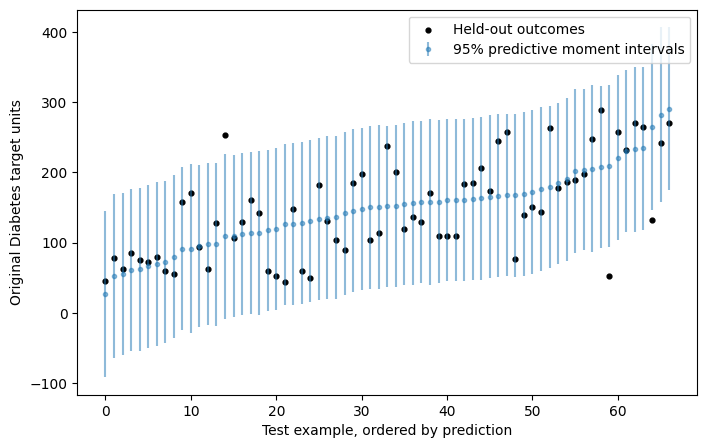

Coverage 0.9552238805970149


In [3]:
from sampling_lab.posterior import predict
from sklearn.datasets import load_diabetes
name="regression_nuts_dispersed_0.1";source=numeric(name);data=load_diabetes();idx=source["test_indices"]
out=predict(ROOT/"assets/source_data"/(name+".npz"),data.data[idx],"regression")
mean=out["mean"];observed=data.target[idx]
fig,ax=plt.subplots(figsize=(8,5));order=np.argsort(mean);ax.errorbar(np.arange(len(mean)),mean[order],yerr=[mean[order]-out["lower"][order],out["upper"][order]-mean[order]],fmt="o",ms=3,alpha=.5,label="95% predictive moment intervals");ax.scatter(np.arange(len(mean)),observed[order],s=12,c="black",label="Held-out outcomes");ax.legend();ax.set(xlabel="Test example, ordered by prediction",ylabel="Original Diabetes target units");plt.show()
print("Coverage",np.mean((observed>=out["lower"])&(observed<=out["upper"])))

## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.